In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
orig_df = pd.read_csv('C:\\Users\\joshua\\OneDrive\\Desktop\\Data Analysis Projects\\netflix.csv')
df = orig_df.copy()

print('Copy Successful!')

Copy Successful!


In [3]:
#use to know column names and its datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Titles       50 non-null     object 
 1   Year         50 non-null     int64  
 2   Rating       50 non-null     object 
 3   IMDB_Rating  50 non-null     float64
 4   Netflix      50 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 2.1+ KB


In [4]:
#use to know column names existed in data set
df.head()

,Titles,Year,Rating,IMDB_Rating,Netflix
0,Breaking Bad,2008,18+,9.5,1
1,Game of Thrones,2011,18+,9.3,0
2,Rick and Morty,2013,18+,9.2,0
3,Dark,2017,16+,8.8,1
4,Stranger Things,2016,16+,8.8,1


In [5]:
#use to print sample of data in the data set
print(df.sample(5))

                               Titles  Year Rating  IMDB_Rating  Netflix
44                            Mad Men  2007    16+          8.6        0
32                   The Walking Dead  2010    18+          8.2        1
49  It's Always Sunny in Philadelphia  2005    18+          8.8        0
40                             Fringe  2008    16+          8.4        0
2                      Rick and Morty  2013    18+          9.2        0


In [6]:
#use to know missing values in dataset
df.isnull().sum()

Titles         0
Year           0
Rating         0
IMDB_Rating    0
Netflix        0
dtype: int64

In [7]:
#use this to know the number of rows and columns in dataset
print('Rows, Columns', df.shape, sep='\n')

Rows, Columns
(50, 5)


In [8]:
#use to know the count of each rating category
print(df['Rating'].value_counts())

Rating
18+    27
16+    19
7+      4
Name: count, dtype: int64


In [9]:
#use to know how many titles are available on Netflix
print(df['Netflix'].value_counts())
print('Netflix share: {:.1f}%'.format(df['Netflix'].mean() * 100))

Netflix
0    31
1    19
Name: count, dtype: int64
Netflix share: 38.0%


In [10]:
#use to preview the highest rated titles
top_rated = df.sort_values('IMDB_Rating', ascending=False)
print(top_rated.head(10))

                              Titles  Year Rating  IMDB_Rating  Netflix
0                       Breaking Bad  2008    18+          9.5        1
7                          Chernobyl  2019    18+          9.4        0
15                  Band of Brothers  2001    18+          9.4        0
1                    Game of Thrones  2011    18+          9.3        0
11                          The Wire  2002    18+          9.3        0
22                      The Sopranos  1999    18+          9.2        0
5         Avatar: The Last Airbender  2005     7+          9.2        1
2                     Rick and Morty  2013    18+          9.2        0
6                           Sherlock  2010    16+          9.1        1
45  Fullmetal Alchemist: Brotherhood  2009    18+          9.1        0


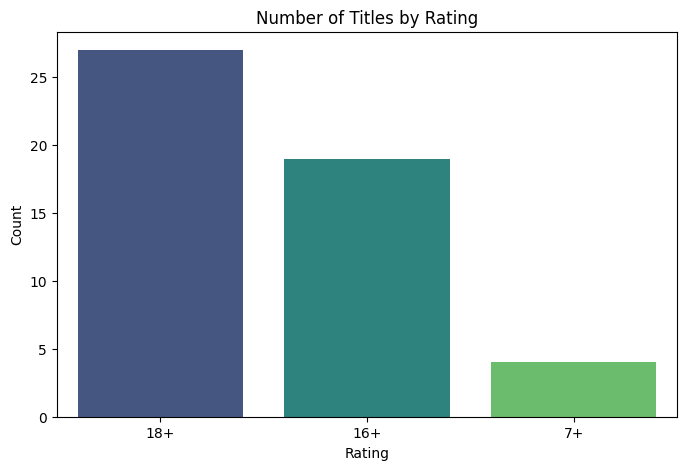

In [11]:
#visualize the number of titles per rating (age rating)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Rating', hue='Rating', palette='viridis', legend=False)
plt.title('Number of Titles by Rating')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

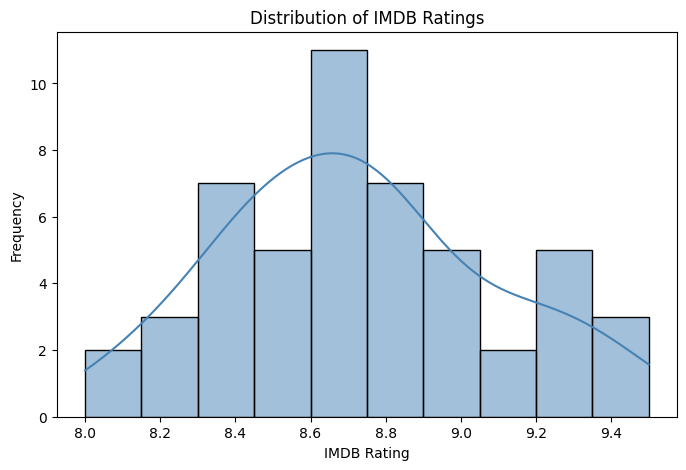

In [12]:
#visualize the distribution of IMDB ratings
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='IMDB_Rating', bins=10, kde=True, color='steelblue')
plt.title('Distribution of IMDB Ratings')
plt.xlabel('IMDB Rating')
plt.ylabel('Frequency')
plt.show()

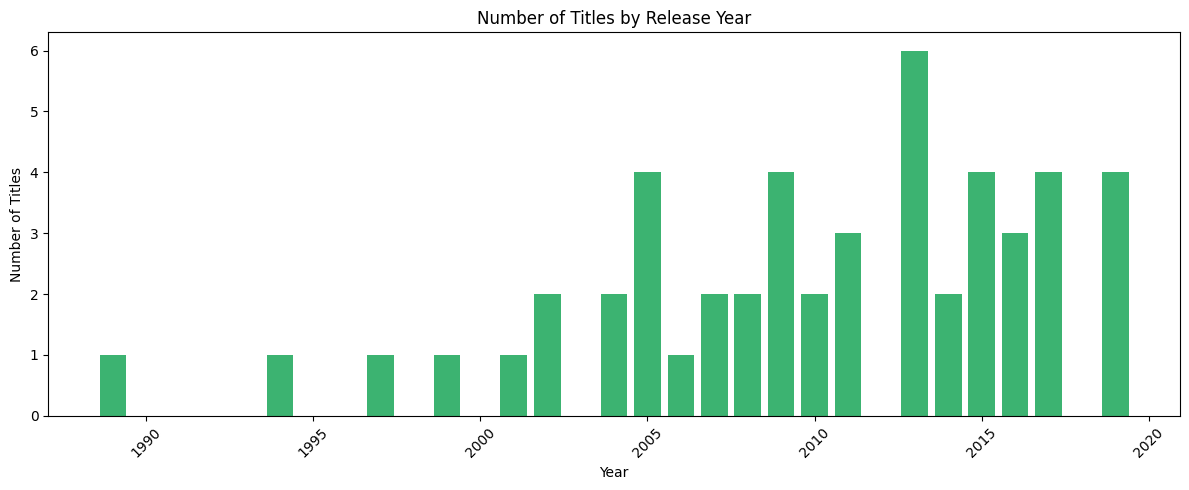

In [13]:
#visualize the number of titles released per year
titles_per_year = df['Year'].value_counts().sort_index()
plt.figure(figsize=(12, 5))
plt.bar(titles_per_year.index, titles_per_year.values, color='mediumseagreen')
plt.title('Number of Titles by Release Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

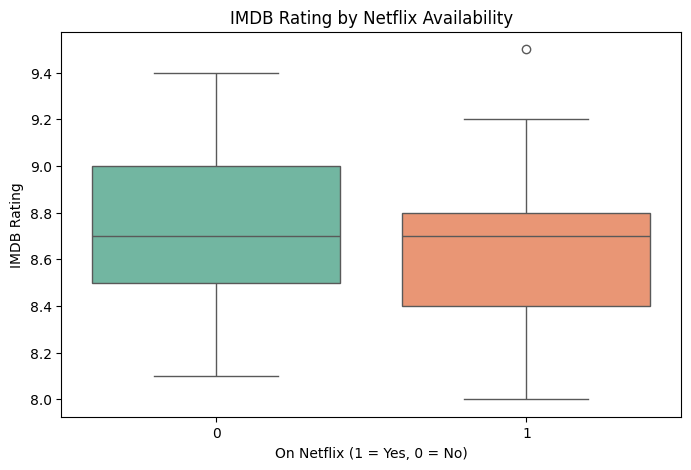

In [14]:
#compare IMDB ratings of titles available on Netflix vs not
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Netflix', y='IMDB_Rating', hue='Netflix', palette='Set2', legend=False)
plt.title('IMDB Rating by Netflix Availability')
plt.xlabel('On Netflix (1 = Yes, 0 = No)')
plt.ylabel('IMDB Rating')
plt.show()

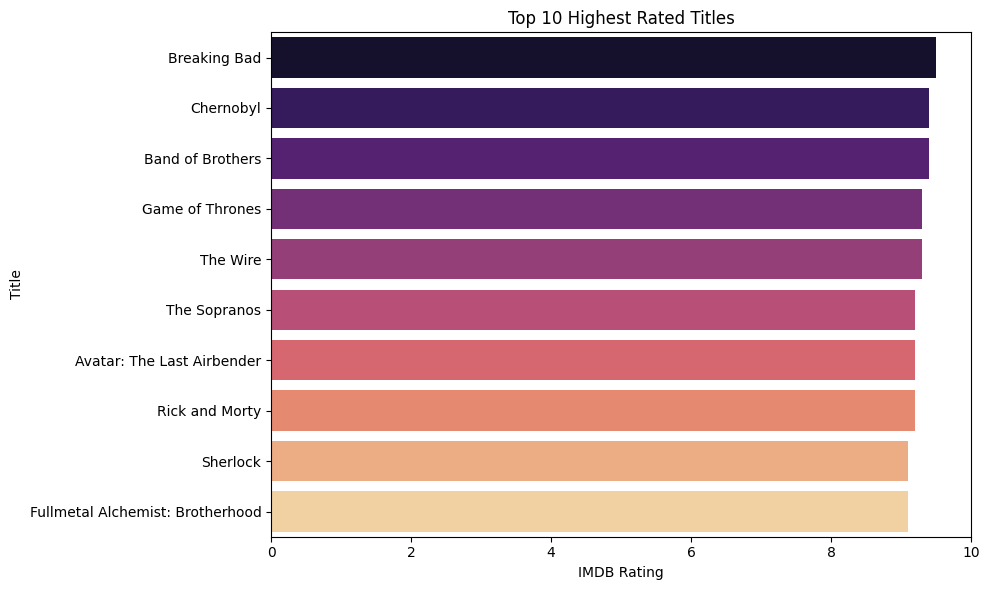

In [15]:
#visualize the ten highest rated titles
top10 = df.sort_values('IMDB_Rating', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=top10, x='IMDB_Rating', y='Titles', hue='Titles', palette='magma', legend=False)
plt.title('Top 10 Highest Rated Titles')
plt.xlabel('IMDB Rating')
plt.ylabel('Title')
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

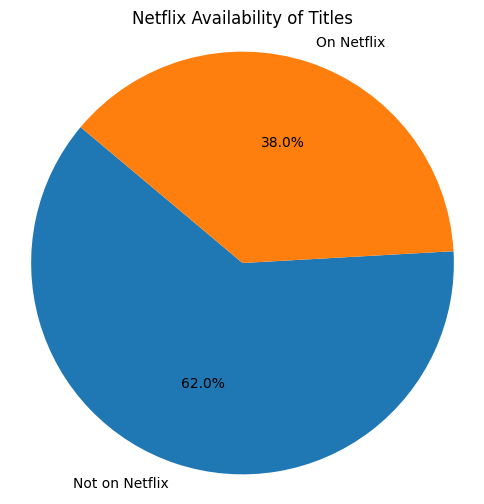

In [16]:
#visualize how many titles are available on Netflix
netflix_counts = df['Netflix'].value_counts()
netflix_labels = netflix_counts.index.map({0: 'Not on Netflix', 1: 'On Netflix'})
plt.figure(figsize=(6, 6))
plt.pie(netflix_counts, labels=netflix_labels, autopct='%1.1f%%', startangle=140)
plt.title('Netflix Availability of Titles')
plt.axis('equal')
plt.show()

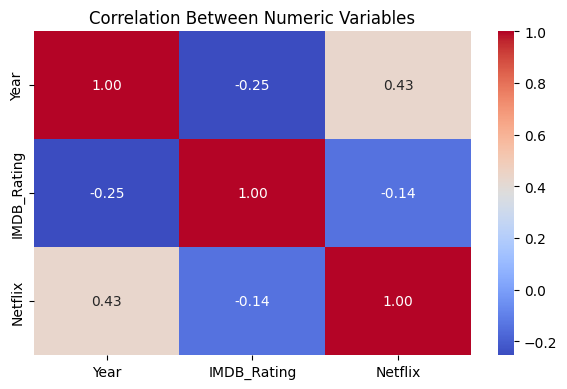

In [17]:
#visualize the correlation between the numeric variables
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Year', 'IMDB_Rating', 'Netflix']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Between Numeric Variables')
plt.tight_layout()
plt.show()